# 24장 · 포논 — 예제 풀이

**열및통계물리2 · 교재 24장 포논 (Blundell & Blundell, *Concepts in Thermal Physics* 2판)**

교재 예제 24.1–24.3과 추가 문제(연습문제 24.1)를 Python으로 확인한다. 위에서부터 순서대로 실행하면 된다.
몰 열용량은 강의자료처럼 $C_V$로 쓴다(교재 기호 $C$). 단위는 SI, 그래프 라벨은 영어로 쓴다.

In [1]:
# ── 0. 준비: 라이브러리와 물리 상수 ──────────────────────────────
import numpy as np
import scipy.constants as sc
from scipy import integrate, optimize, special
import matplotlib.pyplot as plt

# 물리 상수 (SI 단위). 출처: scipy.constants = CODATA 2018 권장값
kB   = sc.k            # 볼츠만 상수 [J/K]
h    = sc.h            # 플랑크 상수 [J s]
hbar = sc.hbar         # [J s]
c    = sc.c            # 광속 [m/s]
e    = sc.e            # 기본 전하 [C]  (1 eV = e J)
NA   = sc.N_A          # 아보가드로 수 [1/mol]
R    = sc.R            # 기체 상수 [J/(mol K)]
me   = sc.m_e          # 전자 질량 [kg]
mp   = sc.m_p          # 양성자 질량 [kg]
amu  = sc.atomic_mass  # 원자 질량 단위 u [kg]
muB  = sc.physical_constants['Bohr magneton'][0]   # 보어 자기량 [J/T]
mu0  = sc.mu_0         # 진공 투자율 [N/A^2]
sigma_SB = sc.Stefan_Boltzmann                      # 스테판-볼츠만 상수 [W m^-2 K^-4]

plt.rcParams.update({'figure.figsize': (6.4, 4.0), 'axes.grid': True, 'grid.alpha': 0.3})

def compare(label, value, book, unit='', rtol=0.05):
    """계산값과 교재 답을 나란히 출력한다. rtol: 허용 상대오차 (교재 답은 보통 유효숫자 2자리)."""
    rel = abs(value - book) / abs(book)
    flag = 'OK' if rel <= rtol else 'CHECK'
    print(f'{label}: computed = {value:.4g} {unit} | textbook = {book:.4g} {unit} | rel. diff = {rel:.2%} [{flag}]')
    return rel

print('Setup complete. numpy', np.__version__)

Setup complete. numpy 2.5.3


## 예제 24.1 — 아인슈타인 고체의 몰 열용량 (교재 364쪽)

**문제 요약.** $U_m=3R\Theta_E\left[\tfrac12+\dfrac{1}{e^{\Theta_E/T}-1}\right]$ (24.6)에서 $C_V=\partial U_m/\partial T$를 구하고 고온·저온 극한을 확인한다. 교재 결과: $C_V=3R\dfrac{x^2e^x}{(e^x-1)^2}$, $x=\Theta_E/T$ (24.8). 고온 $3R$, 저온 $3Rx^2e^{-x}$.

**풀이 아이디어.** $U_m$을 수치미분한 값과 (24.8)을 비교하고, 두 극한을 그래프로 확인한다. $\Theta_E=200$ K로 둔다(입력값).

T =    10 K: dU/dT = 0.000021, eq. (24.8) = 0.000021 J/(mol K);  low-T approx 3R x^2 e^-x = 0.000021
T =    50 K: dU/dT = 7.584968, eq. (24.8) = 7.584968 J/(mol K);  low-T approx 3R x^2 e^-x = 7.309665
T =   200 K: dU/dT = 22.964719, eq. (24.8) = 22.964719 J/(mol K);  low-T approx 3R x^2 e^-x = 9.176160
T =  1000 K: dU/dT = 24.860409, eq. (24.8) = 24.860409 J/(mol K);  low-T approx 3R x^2 e^-x = 0.816877
high-T limit: C(1e5 K) / 3R = 1.000000


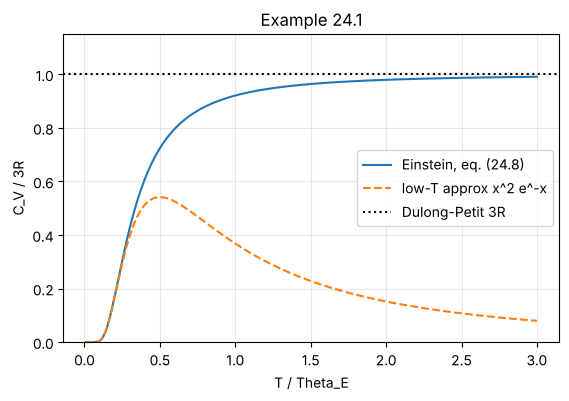

In [2]:
thE = 200.0
U_E = lambda T: 3 * R * thE * (0.5 + 1 / np.expm1(thE / T))          # (24.6) [J/mol]
C_E = lambda T: 3 * R * (thE / T)**2 * np.exp(thE / T) / np.expm1(thE / T)**2   # (24.8)
for T in (10, 50, 200, 1000):
    dT = T * 1e-6
    dUdT = (U_E(T + dT) - U_E(T - dT)) / (2 * dT)
    x = thE / T
    print(f'T = {T:5d} K: dU/dT = {dUdT:.6f}, eq. (24.8) = {C_E(T):.6f} J/(mol K);  low-T approx 3R x^2 e^-x = {3*R*x*x*np.exp(-x):.6f}')
print(f'high-T limit: C(1e5 K) / 3R = {C_E(1e5) / (3 * R):.6f}')
Ts = np.linspace(2, 600, 400)
plt.plot(Ts / thE, C_E(Ts) / (3 * R), label='Einstein, eq. (24.8)')
plt.plot(Ts / thE, (thE / Ts)**2 * np.exp(-thE / Ts), '--', label='low-T approx x^2 e^-x')
plt.axhline(1, ls=':', c='k', label='Dulong-Petit 3R'); plt.ylim(0, 1.15)
plt.xlabel('T / Theta_E'); plt.ylabel('C_V / 3R'); plt.legend(); plt.title('Example 24.1'); plt.show()

**해석.** 수치미분과 식 (24.8)이 일치한다. 고온에서는 $3R$(뒬롱–프티)로 가고, 저온에서는 $x^2e^{-x}$처럼 지수적으로 줄어든다($T=10$ K에서 근사식과 거의 같음). 모든 모드가 같은 진동수라 한꺼번에 얼어붙기 때문이다.

## 예제 24.2 — 데바이 고체의 몰 열용량 (교재 366–367쪽)

**문제 요약.** 데바이 상태밀도 $g(\omega)=9N\omega^2/\omega_D^3$ (24.17)과 진동자 하나의 에너지에서 $U=\tfrac98N\hbar\omega_D+\dfrac{9N\hbar}{\omega_D^3}\int_0^{\omega_D}\dfrac{\omega^3d\omega}{e^{\beta\hbar\omega}-1}$ (24.22)를 얻고, 이를 미분해 $C_V=\dfrac{9R}{x_D^3}\int_0^{x_D}\dfrac{x^4e^x}{(e^x-1)^2}dx$ (24.25)를 유도한다.

**풀이 아이디어.** 몰당 $U(T)$를 수치적분으로 계산해 $T$로 수치미분한 값과 식 (24.25)를 비교한다. 영점에너지 항은 $T$와 무관하므로 미분하면 사라진다. $\Theta_D=394$ K (교재 366쪽 표의 Al)로 둔다.

T =    10 K: dU/dT =   0.031780,  eq. (24.25) =   0.031780 J/(mol K)
T =    50 K: dU/dT =   3.580740,  eq. (24.25) =   3.580740 J/(mol K)
T =   150 K: dU/dT =  18.082392,  eq. (24.25) =  18.082392 J/(mol K)
T =   394 K: dU/dT =  23.739424,  eq. (24.25) =  23.739424 J/(mol K)
T =  1000 K: dU/dT =  24.750851,  eq. (24.25) =  24.750851 J/(mol K)


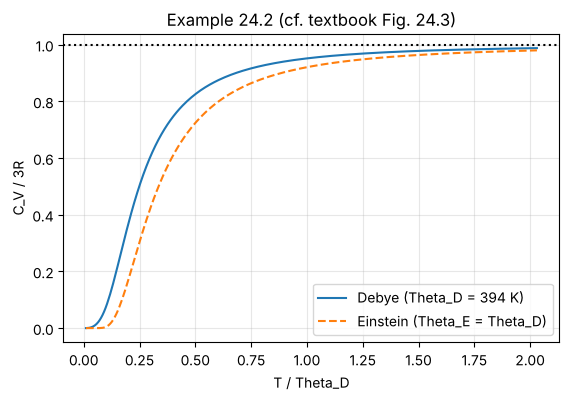

In [3]:
thD = 394.0            # Al (교재 366쪽 표)
def U_D(T):
    """몰당 데바이 내부에너지 [J/mol] (식 24.22를 x = hbar omega / k_B T 로 바꾼 것; 영점 항 포함)"""
    xD = thD / T
    I = integrate.quad(lambda x: x**3 / np.expm1(x), 0, xD, epsabs=0, epsrel=1e-12)[0]
    return 9 / 8 * R * thD + 9 * R * T * (T / thD)**3 * I
def C_D(T):
    """식 (24.25)"""
    xD = thD / T
    I = integrate.quad(lambda x: x**4 * np.exp(x) / np.expm1(x)**2 if x > 1e-8 else x**2, 0, min(xD, 200), epsabs=0, epsrel=1e-12)[0]
    return 9 * R / xD**3 * I
for T in (10, 50, 150, 394, 1000):
    dT = T * 1e-5
    print(f'T = {T:5d} K: dU/dT = {(U_D(T + dT) - U_D(T - dT)) / (2 * dT):10.6f},  eq. (24.25) = {C_D(T):10.6f} J/(mol K)')
Ts = np.linspace(4, 800, 300)
plt.plot(Ts / thD, [C_D(T) / (3 * R) for T in Ts], label='Debye (Theta_D = 394 K)')
plt.plot(Ts / thD, [3 * R * (thD / T)**2 * np.exp(thD / T) / np.expm1(thD / T)**2 / (3 * R) for T in Ts], '--', label='Einstein (Theta_E = Theta_D)')
plt.axhline(1, ls=':', c='k')
plt.xlabel('T / Theta_D'); plt.ylabel('C_V / 3R'); plt.legend(); plt.title('Example 24.2 (cf. textbook Fig. 24.3)'); plt.show()

**해석.** $U$를 수치미분한 값이 식 (24.25)와 일치하므로, 영점에너지 $\tfrac98N\hbar\omega_D$는 열용량에 기여하지 않는다는 교재의 설명도 확인된다. 같은 특성온도로 비교하면 저온에서 데바이 곡선이 아인슈타인 곡선보다 훨씬 천천히 줄어든다(교재 그림 24.3).

## 예제 24.3 — 데바이 열용량의 극한 (교재 368쪽)

**문제 요약.** 식 (24.25)에서 고온($x_D\ll1$, $e^x-1\approx x$)이면 $C_V\to3R$ (24.26), 저온($x_D\gg1$, 상한을 ∞로)이면 $\int_0^\infty\dfrac{x^4e^x}{(e^x-1)^2}dx=\dfrac{4\pi^4}{15}$을 써서 $C_V\to\dfrac{12\pi^4R}{5}\left(\dfrac{T}{\Theta_D}\right)^3$ (24.27, 24.28)이다.

**풀이 아이디어.** 적분값 $4\pi^4/15$와 계수 $12\pi^4/5\approx233.8$을 수치로 확인하고, 로그-로그 그래프에서 $T^3$ 영역을 본다.

integral x^4 e^x/(e^x-1)^2 from 0 to inf: computed = 25.98  | textbook = 25.98  | rel. diff = 0.00% [OK]
coefficient 12 pi^4 / 5 = 233.7818
T/Theta_D =  0.01: C_D / [ (12 pi^4/5) R (T/Theta_D)^3 ] = 1.00000
T/Theta_D =  0.02: C_D / [ (12 pi^4/5) R (T/Theta_D)^3 ] = 1.00000
T/Theta_D =  0.05: C_D / [ (12 pi^4/5) R (T/Theta_D)^3 ] = 0.99998
T/Theta_D =  0.10: C_D / [ (12 pi^4/5) R (T/Theta_D)^3 ] = 0.97297
high T: C_D(50 Theta_D) / 3R = 0.999980


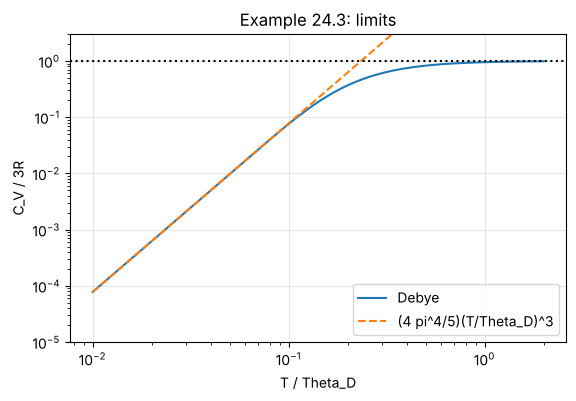

In [4]:
I_inf = integrate.quad(lambda x: x**4 * np.exp(x) / np.expm1(x)**2 if x > 1e-8 else x**2, 0, 200, epsabs=0, epsrel=1e-12)[0]
compare('integral x^4 e^x/(e^x-1)^2 from 0 to inf', I_inf, 4 * np.pi**4 / 15, '', rtol=1e-6)
print(f'coefficient 12 pi^4 / 5 = {12 * np.pi**4 / 5:.4f}')
for r in (0.01, 0.02, 0.05, 0.1):
    print(f'T/Theta_D = {r:5.2f}: C_D / [ (12 pi^4/5) R (T/Theta_D)^3 ] = {C_D(r * thD) / (12 * np.pi**4 / 5 * R * r**3):.5f}')
print(f'high T: C_D(50 Theta_D) / 3R = {C_D(50 * thD) / (3 * R):.6f}')
rs = np.logspace(-2, 0.3, 200)
plt.loglog(rs, [C_D(r * thD) / (3 * R) for r in rs], label='Debye')
plt.loglog(rs, 4 * np.pi**4 / 5 * rs**3, '--', label='(4 pi^4/5)(T/Theta_D)^3')
plt.axhline(1, ls=':', c='k'); plt.ylim(1e-5, 3)
plt.xlabel('T / Theta_D'); plt.ylabel('C_V / 3R'); plt.legend(); plt.title('Example 24.3: limits'); plt.show()

**해석.** 적분은 정확히 $4\pi^4/15$이고, $T/\Theta_D\lesssim0.05$에서 데바이 열용량이 $T^3$ 법칙과 0.01 % 안에서 같다. 고온에서는 $3R$로 간다. 두 극한의 적용 조건($T\ll\Theta_D$, $T\gg\Theta_D$)을 함께 기억해야 한다.

## 추가 문제 — 연습문제 24.1: 최대 포논 진동수와 소리 속력 (교재 372쪽)

**문제 요약.** 격자상수 0.3 nm인 단순입방 결정의 데바이 온도가 100 K일 때, 최대 포논 진동수(Hz)와 소리 속력(m/s)을 예측한다. 교재에 수치 답은 없다.

**풀이 아이디어.** $\Theta_D=\hbar\omega_D/k_B$ (24.18)에서 $\omega_D$, $\nu_D=\omega_D/2\pi$를 구한다. 단순입방은 원자 하나당 부피 $a^3$이므로 $N/V=1/a^3$이고, $\omega_D=(6\pi^2v_s^3N/V)^{1/3}$ (24.16)에서 $v_s=\omega_D\,a/(6\pi^2)^{1/3}$이다.

In [5]:
a, thD1 = 0.3e-9, 100.0
wD = kB * thD1 / hbar
nuD = wD / (2 * np.pi)
vs = wD * a / (6 * np.pi**2) ** (1 / 3)
print(f'omega_D = {wD:.3e} rad/s,  nu_D = {nuD:.3e} Hz = {nuD / 1e12:.2f} THz')
print(f'speed of sound v_s = {vs:.0f} m/s')

omega_D = 1.309e+13 rad/s,  nu_D = 2.084e+12 Hz = 2.08 THz
speed of sound v_s = 1008 m/s


**해석.** 최대 포논 진동수는 약 2 THz(적외선 영역)이고, 소리 속력은 약 1000 m/s이다. 데바이 온도가 낮은 물질일수록 원자가 무겁거나 결합이 약해 소리가 느리다.